# 05 — Houle hivernale et prévision tous les 5 jours

Deux pistes testées pour mieux prévoir les échouages :

1. **La houle de l'hiver** (novembre à mars, au large de chaque baie, réanalyse ERA5 des vagues) :
   un hiver agité disperse le stock d'ulves. C'est le premier facteur cité par le CEVA.
2. **Un système de prévision à 5 jours** : à chaque date, dernière image satellite claire + marée prévue
   + météo, débits, azote (et houle) → surface d'ulves à J+5. En additionnant mai, juillet et septembre,
   on obtient un cumul « façon CEVA » à comparer aux cumuls officiels.

Données produites par :
```bash
python scripts/ingest.py                                     # table annuelle, avec houle
python scripts/affiner_s2.py --toutes-claires                # surfaces corrigées de ~900 images
python scripts/prevision_5j_experimentale.py <version> --maree <daily_risk.parquet>
```
La marée prévue (hauteur d'eau à 11 h UTC, marégraphes SHOM) vient pour l'instant de la branche
`feature/daily-risk` d'Allan. Pour Concarneau, la marée de Brest sert d'approximation.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
warnings.filterwarnings("ignore")
pd.plotting.register_matplotlib_converters()
RACINE = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RACINE / "src"))
from algathon.series_annuelles import charger_config
P = RACINE / "data" / "processed"
noms = {k: b["nom"].split("(")[0].strip().replace("Baies de Concarneau et de La Forêt-Fouesnant", "Concarneau et La Forêt")
        for k, b in charger_config()["baies"].items()}
t = pd.read_csv(P / "baies_annuel.csv")
VERSIONS = {"brut": "Surfaces brutes", "corrige": "Surfaces corrigées", "corrige_houle": "Corrigées + houle"}

## 1. La houle de l'hiver explique-t-elle les bonnes et mauvaises années ?

In [2]:
a = t.dropna(subset=["surface_ha"]).copy()
a["ecart"] = np.log1p(a.surface_ha) - a.groupby("baie").surface_ha.transform(lambda s: np.log1p(s).mean())
corr = a.groupby("baie").apply(lambda g: pd.Series({
    "années": len(g),
    "houle moyenne": g.ecart.corr(g.houle_hiver_moy, method="spearman"),
    "jours > 2,5 m": g.ecart.corr(g.jours_houle_25, method="spearman"),
    "jours > 3,5 m": g.ecart.corr(g.jours_houle_35, method="spearman"),
    "jours > 4,5 m": g.ecart.corr(g.jours_houle_45, method="spearman")}))
corr.index = [noms[b] for b in corr.index]
corr.round(2).style.background_gradient(cmap="RdBu_r", vmin=-0.6, vmax=0.6, subset=corr.columns[1:])

,années,houle moyenne,"jours > 2,5 m","jours > 3,5 m","jours > 4,5 m"
Concarneau et La Forêt,20.000000,-0.340000,-0.360000,-0.250000,0.070000
Baie de Douarnenez,19.000000,-0.410000,-0.520000,-0.230000,0.050000
Baie de la Fresnaye,15.000000,0.020000,-0.070000,0.000000,0.140000
Anse de Guissény,21.000000,0.430000,0.420000,0.460000,0.510000
Anse de l'Horn et du Guillec,21.000000,0.190000,0.280000,0.180000,0.120000
Lieue de Grève,21.000000,-0.160000,-0.220000,-0.060000,-0.270000
Baie de Saint-Brieuc,21.000000,-0.010000,0.030000,-0.060000,-0.020000


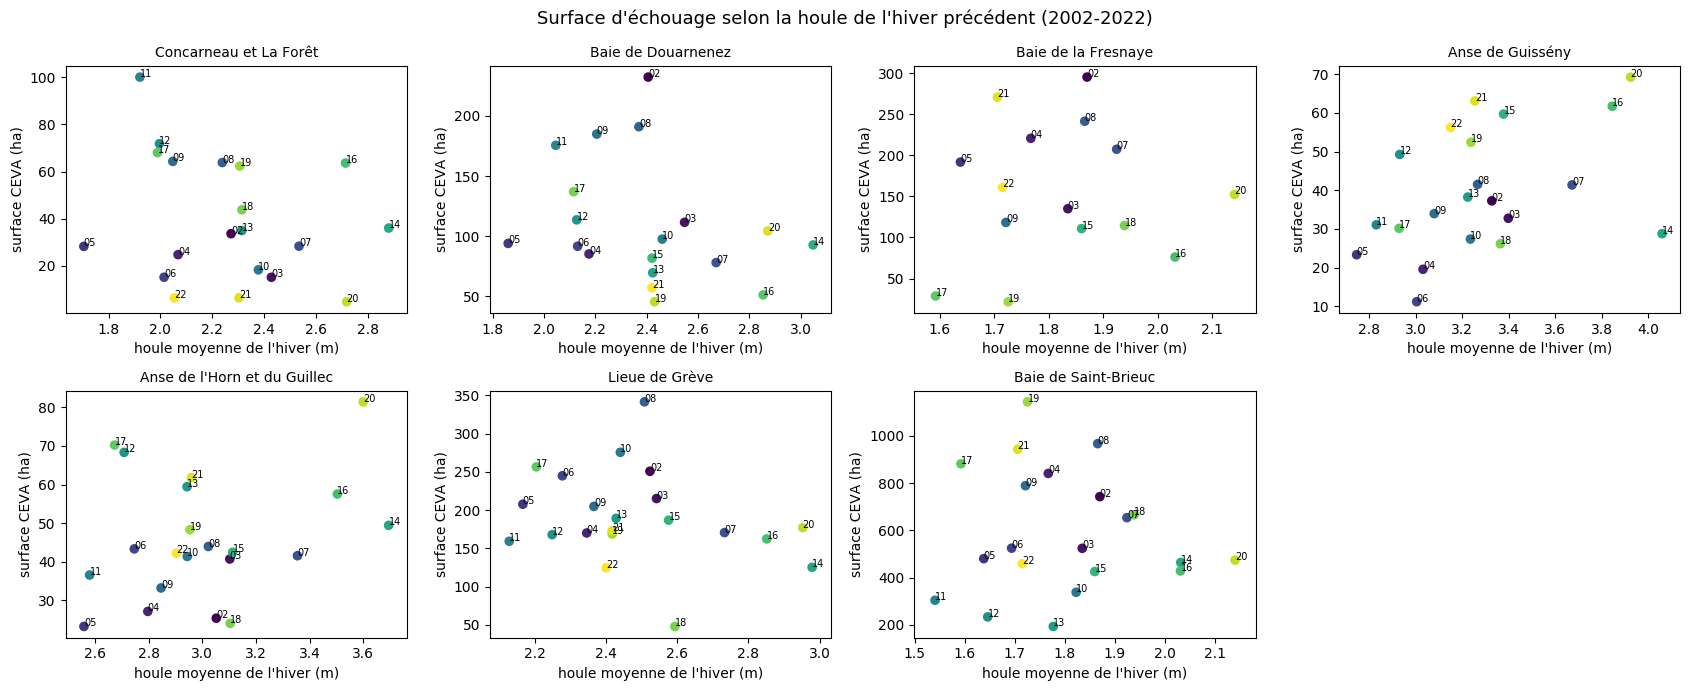

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, (b, g) in zip(axes.flat, a.groupby("baie")):
    ax.scatter(g.houle_hiver_moy.values, g.surface_ha.values, c=g.annee.values, cmap="viridis", s=35)
    for _, r in g.iterrows():
        ax.annotate(str(int(r.annee))[2:], (r.houle_hiver_moy, r.surface_ha), fontsize=7)
    ax.set_title(noms[b], fontsize=10); ax.set_xlabel("houle moyenne de l'hiver (m)"); ax.set_ylabel("surface CEVA (ha)")
axes.flat[-1].axis("off")
fig.suptitle("Surface d'échouage selon la houle de l'hiver précédent (2002-2022)", fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.95])

**Lecture** : le lien attendu (hiver agité → moins d'algues) n'apparaît qu'à Douarnenez et Concarneau ;
il est inversé à Guissény et absent à Saint-Brieuc sur 20 ans (les années record 2017, 2019 et 2021 suivent
bien des hivers calmes, mais ce schéma ne tient pas sur 2002-2016).

Dans le modèle annuel combiné (Extra Trees sur écarts + Ridge d'Allan), la houle ne fait pas mieux de
façon fiable : en fenêtre glissante, le gain sur la surface habituelle passe de +2,1 % à +0,5 % ; en
« une année laissée de côté », de +1,8 % à +2,4 % (+3,5 % avec la seule houle et l'an dernier).

## 2. Prévision à 5 jours : qualité selon la version

In [4]:
lignes = []
for v, nom in VERSIONS.items():
    e = pd.read_csv(P / "prevision_5j" / (v + "_sys5j_eval.csv")).dropna(subset=["p_saison"])
    vrai = np.expm1(e.l_ulve1)
    for k, lab in (("p_persistance", "même chose que la dernière image"), ("p_saison", "niveau habituel du mois"), ("p_modele", "système complet")):
        ha = np.expm1(e[k])
        lignes.append({"version": nom, "méthode": lab, "prévisions": len(e), "erreur moyenne (ha)": (ha - vrai).abs().mean(),
                       "à ±50 % (%)": 100 * ((ha >= vrai / 1.5) & (ha <= vrai * 1.5)).mean(),
                       "erreur log": (e[k] - e.l_ulve1).abs().mean()})
q = pd.DataFrame(lignes)
q["gain vs persistance (%)"] = q.groupby("version")["erreur log"].transform(lambda s: 100 * (1 - s / s.iloc[0]))
q.drop(columns="erreur log").round(1)

,version,méthode,prévisions,erreur moyenne (ha),à ±50 % (%),gain vs persistance (%)
0,Surfaces brutes,même chose que la dernière image,557,70.2,21.9,0.0
1,Surfaces brutes,niveau habituel du mois,557,51.5,22.8,24.0
2,Surfaces brutes,système complet,557,29.0,58.7,63.8
3,Surfaces corrigées,même chose que la dernière image,557,32.2,16.7,0.0
4,Surfaces corrigées,niveau habituel du mois,557,23.8,19.6,17.9
5,Surfaces corrigées,système complet,557,18.0,34.6,46.2
6,Corrigées + houle,même chose que la dernière image,557,32.2,16.7,0.0
7,Corrigées + houle,niveau habituel du mois,557,23.8,19.6,17.9
8,Corrigées + houle,système complet,557,18.5,35.4,46.1


Avec les surfaces corrigées, la cible est plus petite et plus bruitée (les rochers stables ont été retirés) :
l'erreur en hectares baisse, mais la part de prévisions à ±50 % aussi. Le gain sur la persistance reste
d'environ 45 %, presque entièrement dû à la **marée prévue**.

## 3. Une saison complète (2019), surfaces corrigées + houle

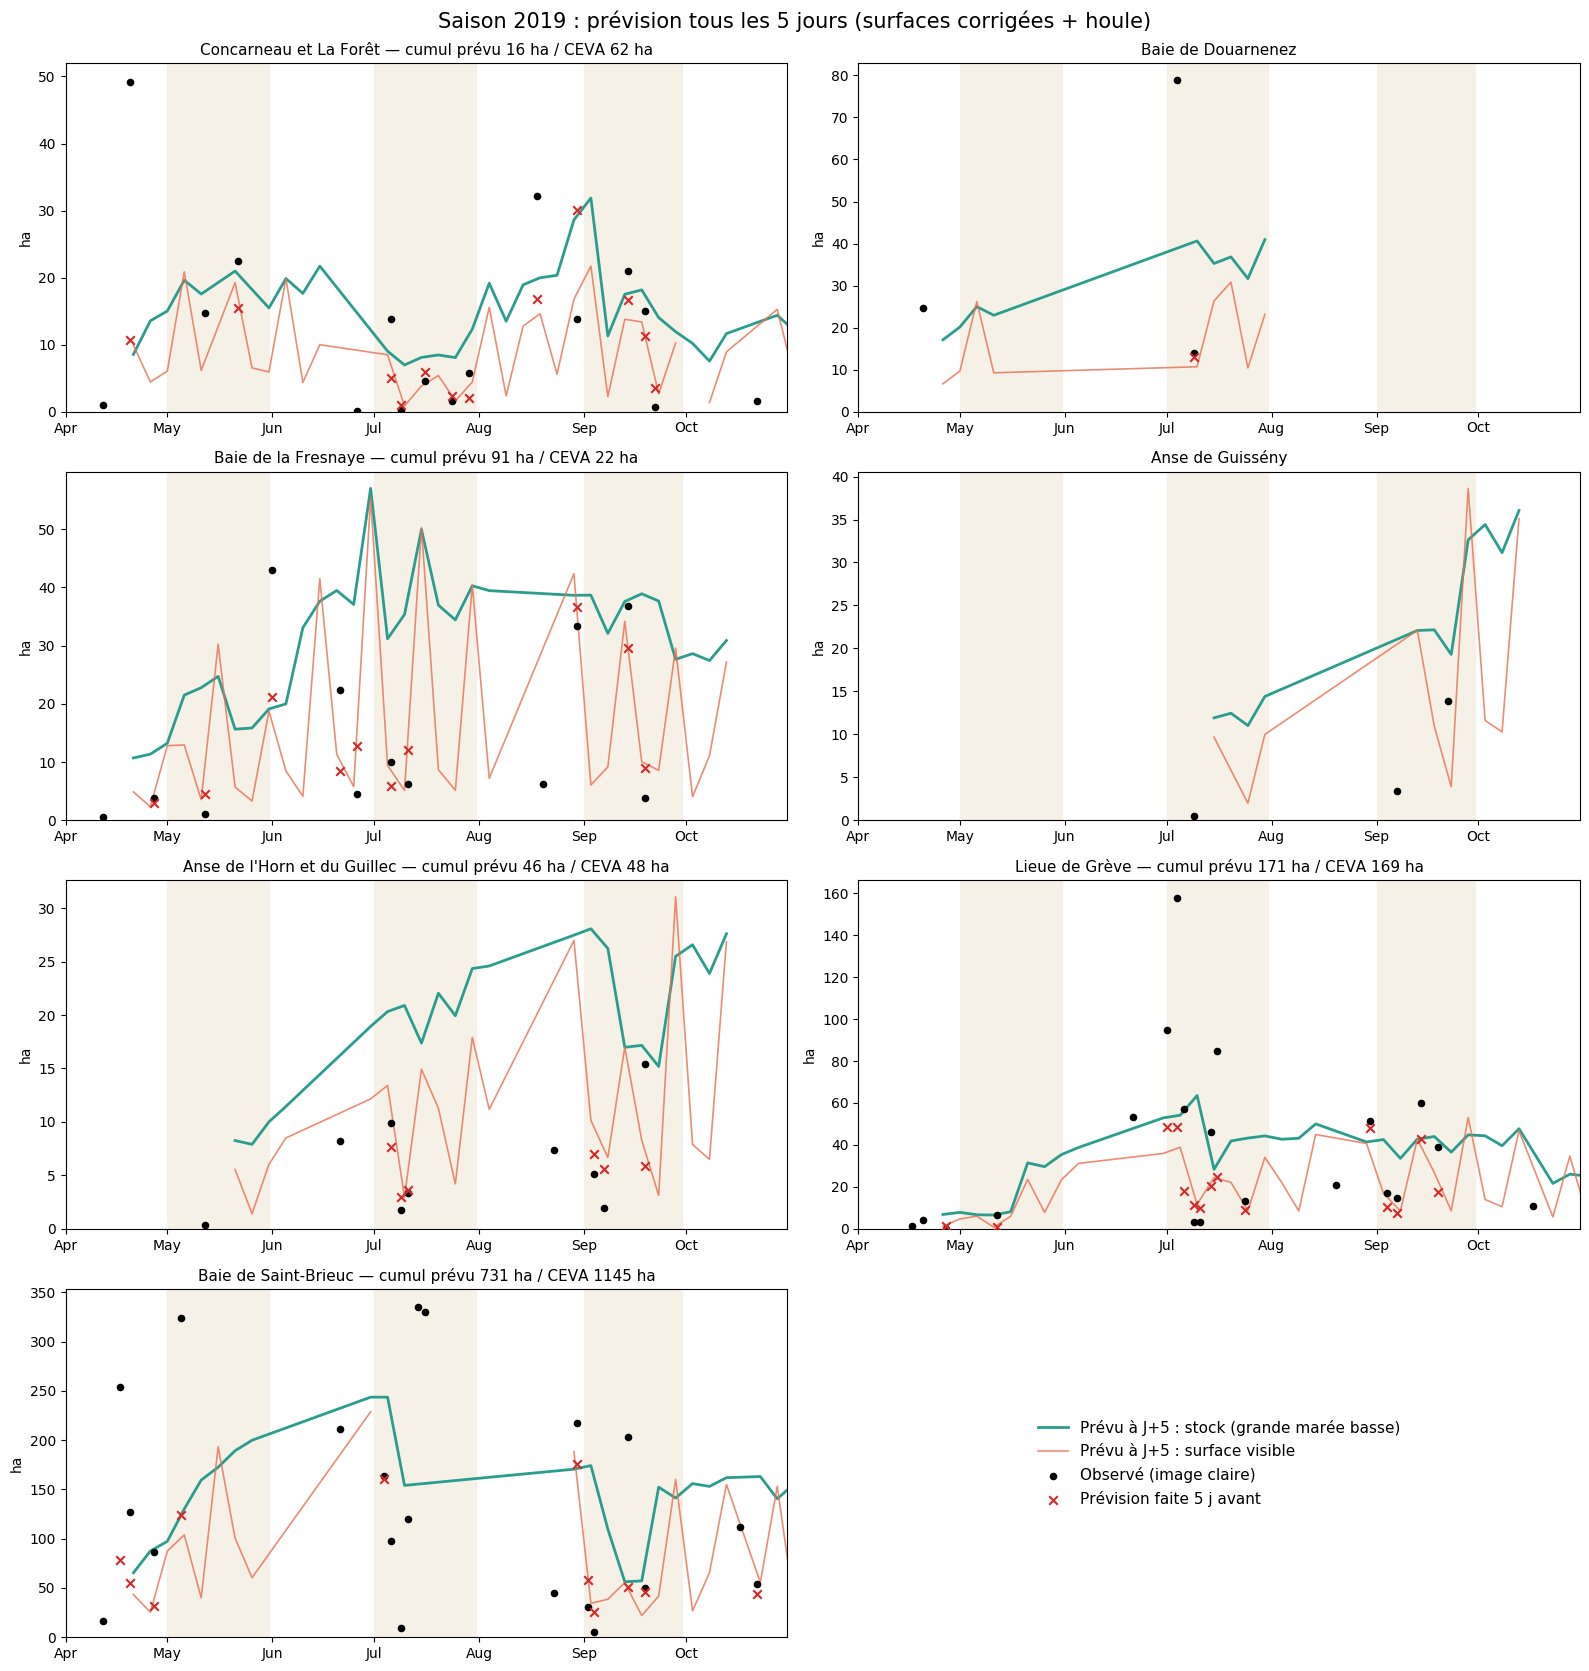

In [5]:
V = "corrige_houle"
e = pd.read_csv(P / "prevision_5j" / (V + "_sys5j_eval.csv"), parse_dates=["date1"])
g = pd.read_csv(P / "prevision_5j" / (V + "_sys5j_courbes.csv"), parse_dates=["date_cible"])
m = pd.read_csv(P / "prevision_5j" / (V + "_sys5j_cumuls.csv"))
s = pd.read_csv(P / "s2_scenes_claires_corrige.csv", parse_dates=["date"])
D = lambda *x: mdates.date2num(pd.Timestamp(*x).to_pydatetime())
dn = lambda ser: mdates.date2num(ser.dt.to_pydatetime())
def saison(Y):
    fig, axes = plt.subplots(4, 2, figsize=(16, 17))
    for ax, b in zip(axes.flat, sorted(noms)):
        gg = g[(g.baie == b) & (g.annee == Y)]; ee = e[(e.baie == b) & (e.annee == Y)]
        ss = s[(s.baie == b) & (s.date.dt.year == Y) & s.date.dt.month.between(4, 10)]
        for mo in (5, 7, 9):
            ax.axvspan(D(Y, mo, 1), D(pd.Timestamp(Y, mo, 1) + pd.offsets.MonthEnd(0)), color="#f6f1e7", zorder=0)
        if len(gg):
            ax.plot(dn(gg.date_cible), gg.basse_mer_ha.values, color="#2a9d8f", lw=2, label="Prévu à J+5 : stock (grande marée basse)")
            ax.plot(dn(gg.date_cible), gg.visible_ha.values, color="#e76f51", lw=1.2, alpha=.8, label="Prévu à J+5 : surface visible")
        if len(ss): ax.scatter(dn(ss.date), ss.ulva_corr_s020.values, color="black", s=20, zorder=5, label="Observé (image claire)")
        if len(ee): ax.scatter(dn(ee.date1), np.expm1(ee.p_modele.values), marker="x", color="#d62828", s=38, zorder=6, label="Prévision faite 5 j avant")
        r = m[(m.baie == b) & (m.annee == Y)]
        txt = ""
        if len(r) and pd.notna(r.cumul_calibre.iloc[0]):
            txt = (" — cumul prévu %.0f ha / CEVA %.0f ha" % (r.cumul_calibre.iloc[0], r.surface_ha.iloc[0])
                   if pd.notna(r.surface_ha.iloc[0]) else " — cumul prévu %.0f ha" % r.cumul_calibre.iloc[0])
        ax.set_title(noms[b] + txt, fontsize=11); ax.set_ylabel("ha"); ax.set_ylim(bottom=0)
        ax.xaxis.set_major_locator(mdates.MonthLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
        ax.set_xlim(D(Y, 4, 1), D(Y, 10, 31))
    axes.flat[-1].axis("off"); h, l = axes.flat[0].get_legend_handles_labels()
    axes.flat[-1].legend(h, l, loc="center", fontsize=11, frameon=False)
    fig.suptitle("Saison %d : prévision tous les 5 jours (surfaces corrigées + houle)" % Y, fontsize=15)
    fig.tight_layout(rect=[0, 0, 1, 0.97])
saison(2019)

## 4. Le cumul de la saison est-il proche du CEVA ?

In [6]:
res = []
for v, nom in VERSIONS.items():
    mm = pd.read_csv(P / "prevision_5j" / (v + "_sys5j_cumuls.csv")).dropna(subset=["surface_ha", "cumul_calibre"])
    res.append({"version": nom, "baies-années": len(mm),
                "ratio brut (avant échelle)": mm.cumul_prevu.sum() / mm.surface_ha.sum(),
                "écart moyen (%)": 100 * (mm.cumul_calibre - mm.surface_ha).abs().sum() / mm.surface_ha.sum(),
                "cumuls à ±50 % (%)": 100 * ((mm.cumul_calibre >= mm.surface_ha / 1.5) & (mm.cumul_calibre <= mm.surface_ha * 1.5)).mean(),
                "suit les années (Spearman moyen par baie)": mm.groupby("baie").apply(lambda g: g.cumul_prevu.corr(g.surface_ha, method="spearman")).mean()})
pd.DataFrame(res).set_index("version").round(2)

,baies-années,ratio brut (avant échelle),écart moyen (%),cumuls à ±50 % (%),suit les années (Spearman moyen par baie)
version,,,,,
Surfaces brutes,25,1.78,46.28,40.0,0.54
Surfaces corrigées,25,0.71,38.68,44.0,0.45
Corrigées + houle,25,0.70,36.97,44.0,0.31


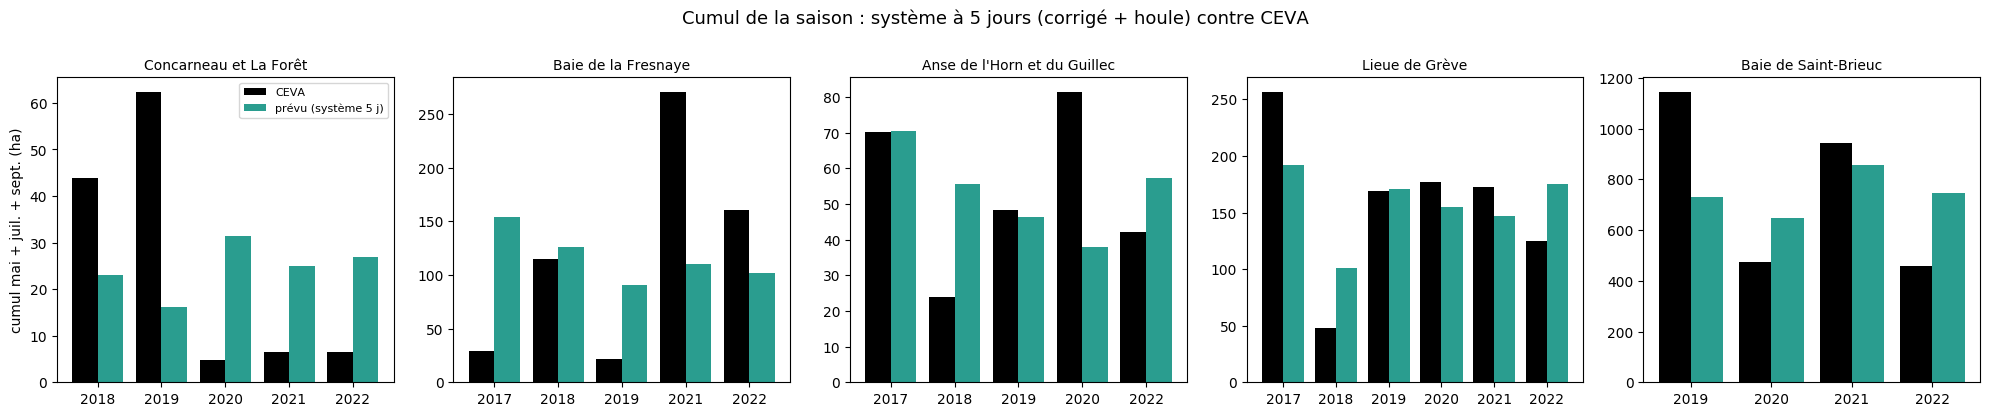

In [7]:
mm = pd.read_csv(P / "prevision_5j" / "corrige_houle_sys5j_cumuls.csv").dropna(subset=["surface_ha", "cumul_calibre"])
bb = sorted(mm.baie.unique())
fig, axes = plt.subplots(1, len(bb), figsize=(4 * len(bb), 4.2))
for ax, b in zip(axes, bb):
    k = mm[mm.baie == b]; x = np.arange(len(k))
    ax.bar(x - 0.2, k.surface_ha.values, 0.4, color="black", label="CEVA")
    ax.bar(x + 0.2, k.cumul_calibre.values, 0.4, color="#2a9d8f", label="prévu (système 5 j)")
    ax.set_xticks(x); ax.set_xticklabels(k.annee.values); ax.set_title(noms[b], fontsize=10)
axes[0].legend(fontsize=8); axes[0].set_ylabel("cumul mai + juil. + sept. (ha)")
fig.suptitle("Cumul de la saison : système à 5 jours (corrigé + houle) contre CEVA", fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.9])

## Ce qu'on retient

- **La correction des algues fixées améliore le cumul de la saison** : le niveau brut devient réaliste
  (Concarneau passe d'un ratio de 16,9 à 1,7), l'écart au CEVA baisse de 46 % à 39 % et 44 % des cumuls
  tombent à ±50 % (40 % avant).
- **La houle hivernale n'apporte rien de fiable**, ni au modèle annuel ni au système à 5 jours (écart 37 %,
  et le suivi des bonnes et mauvaises années se dégrade). Le lien « hiver agité → moins d'algues » n'existe
  que dans 2 baies sur 7.
- **La prévision à 5 jours reste utile** (environ 45 % de mieux que la persistance), surtout grâce à la
  marée prévue ; la météo, les débits, l'azote et la houle n'y pèsent presque rien.
- **Le cumul de la saison retrouve le bon niveau de chaque baie mais suit mal les années** : on ne sait
  toujours pas annoncer une saison exceptionnelle. La limite vient des données (une image claire tous les
  5 à 20 jours, un seul chiffre CEVA par an), pas du modèle.
